# wlmzad04

importy:

In [7]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

funkcuja g jako Lambda, oraz do jej całka:

In [8]:
x, u = sp.symbols("x u", positive=True)
g = sp.sin(x) ** 2 * sp.cos(x) ** 4
g_u = sp.sin(u) ** 2 * sp.cos(u) ** 4
Ig = sp.simplify(sp.integrate(g_u, (u, 0, x)))

print("g(x) =", g)
print("Ig(x) =", Ig)
print("D(Ig) == g:", sp.simplify(sp.diff(Ig, x) - g) == 0)

g(x) = sin(x)**2*cos(x)**4
Ig(x) = x/16 - (cos(2*x) + 1)**2*sin(2*x)/48 + sin(2*x)/24 + sin(4*x)/192
D(Ig) == g: True


Tworzenie wykresu funkcji g i jej całki:

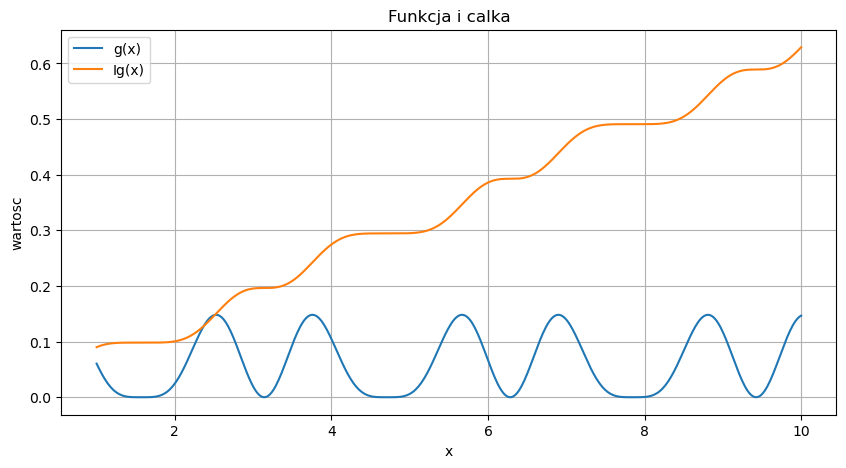

In [9]:
g_num = sp.lambdify(x, g, "numpy")
Ig_num = sp.lambdify(x, Ig, "numpy")


def approx_sum(arg, parts):
    dx = arg / parts
    points = np.arange(parts + 1) * dx
    return dx * np.sum(g_num(points))


xs = np.linspace(1.0, 10.0, 500)

plt.figure(figsize=(10, 5))
plt.plot(xs, g_num(xs), label="g(x)")
plt.plot(xs, Ig_num(xs), label="Ig(x)")
plt.xlabel("x")
plt.ylabel("wartosc")
plt.title("Funkcja i calka")
plt.grid(True)
plt.legend()
plt.show()

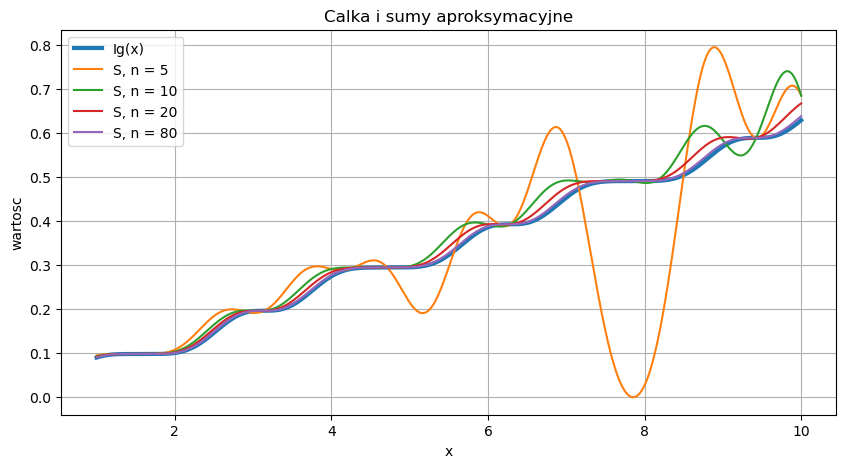

x =  1.0  Ig =   0.08998810  S80 =   0.09036136  blad = 3.733e-04
x =  2.0  Ig =   0.10051089  S80 =   0.10083096  blad = 3.201e-04
x =  5.0  Ig =   0.29488090  S80 =   0.29509194  blad = 2.110e-04
x = 10.0  Ig =   0.62920993  S80 =   0.63847269  blad = 9.263e-03


In [10]:
plt.figure(figsize=(10, 5))
plt.plot(xs, Ig_num(xs), linewidth=3, label="Ig(x)")
for parts in [5, 10, 20, 80]:
    sums = np.array([approx_sum(value, parts) for value in xs])
    plt.plot(xs, sums, label="S, n = " + str(parts))
plt.xlabel("x")
plt.ylabel("wartosc")
plt.title("Calka i sumy aproksymacyjne")
plt.grid(True)
plt.legend()
plt.show()

for point in [1.0, 2.0, 5.0, 10.0]:
    exact = Ig_num(point)
    approx = approx_sum(point, 80)
    print("x = {0:4.1f}  Ig = {1:12.8f}  S80 = {2:12.8f}  blad = {3:.3e}".format(point, exact, approx, abs(exact - approx)))